# **PUMP IT UP 4 - JAIME DE VERA MARTÍN**

---

---



## Me conecto a Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Importo las librerías necesarias

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

from sklearn.ensemble import ExtraTreesClassifier

## Me creo mis DataFrames principales

In [3]:
X_train_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetValues.csv',
                          sep=',',
                          index_col='id',
                          parse_dates=['date_recorded'])

y_train_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetLabels.csv',
                          sep=',',
                          index_col='id')

X_test_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TestSetValues.csv',
                          sep=',',
                          index_col='id',
                          parse_dates=['date_recorded'])

# Mapeo de la variable objetivo a formato numérico
y = y_train_original["status_group"].map({'non functional': 0, 'functional needs repair': 1, 'functional': 2})

print(f"Dimensiones de entrenamiento original: {X_train_original.shape}")

Dimensiones de entrenamiento original: (59400, 39)


## **LIMPIEZA**


In [4]:
def preprocesado_estructural_v2_1(df):
    df_clean = df.copy()

    # Ingeniería de fechas
    df_clean['antiguedad'] = df_clean['date_recorded'].dt.year - df_clean['construction_year']
    df_clean['mes_registro'] = df_clean['date_recorded'].dt.month
    df_clean.drop(columns=['date_recorded', 'construction_year'], inplace=True)

    # Eliminación de redundancias
    columnas_a_borrar = [
        'recorded_by', 'num_private', 'wpt_name', 'scheme_name',
        'subvillage', 'ward', 'lga',
        'extraction_type_group', 'extraction_type_class',
        'management_group', 'scheme_management',
        'payment_type', 'quality_group', 'quantity_group',
        'source_type', 'source_class', 'waterpoint_type_group',
        'funder', 'installer']

    df_clean.drop(columns=columnas_a_borrar, inplace=True, errors='ignore')

    # Caza de ceros y limpieza
    for col in ['longitude', 'population', 'gps_height']:
        df_clean[col] = df_clean[col].replace(0, np.nan)
    df_clean['antiguedad'] = df_clean['antiguedad'].apply(lambda x: np.nan if x > 100 or x < 0 else x)

    # Tanzania no tiene latitudes positivas (error de GPS)
    df_clean['latitude'] = df_clean['latitude'].apply(lambda x: np.nan if x > -1e-6 else x)

    return df_clean

X_clean = preprocesado_estructural_v2_1(X_train_original)
print(f"Dimensiones: {X_clean.shape}")

Dimensiones: (59400, 20)


## **MEJORA DEL PRIMER MODELO DEL NOTEBOOK 2 (PIPELINE) CON UN PUBLIC SCORE DE 0.8119**

In [5]:
# Separación del conjunto de validación
X_train, X_val, y_train, y_val = train_test_split(X_clean, y, test_size=0.2, random_state=42, stratify=y)

num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

# Transformadores
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')) ])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)])

modelo_rf_tuneado = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=500,
        max_depth=25,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1))])

modelo_rf_tuneado.fit(X_train, y_train)

score_val = modelo_rf_tuneado.score(X_val, y_val)
print("-" * 40)
print(f"PRECISIÓN EN VALIDACIÓN: {score_val * 100:.2f}%")
print("-" * 40)

----------------------------------------
PRECISIÓN EN VALIDACIÓN: 81.69%
----------------------------------------


## **INTERPRETABILIDAD DEL MODELADO AUTOMATIZADO**

Al haber restringido la profundidad del árbol (`max_depth=25`) y exigido más muestras para dividirse (`min_samples_split=5`), hemos obligado al modelo a fijarse solo en los patrones más fuertes y generales, ignorando el ruido.

Además, vamos a extraer la importancia de las variables para comprobar si nuestra nueva característica creada manualmente (`mes_registro`) ha logrado captar la estacionalidad de las sequías y averías en Tanzania, colándose entre las variables más importantes.

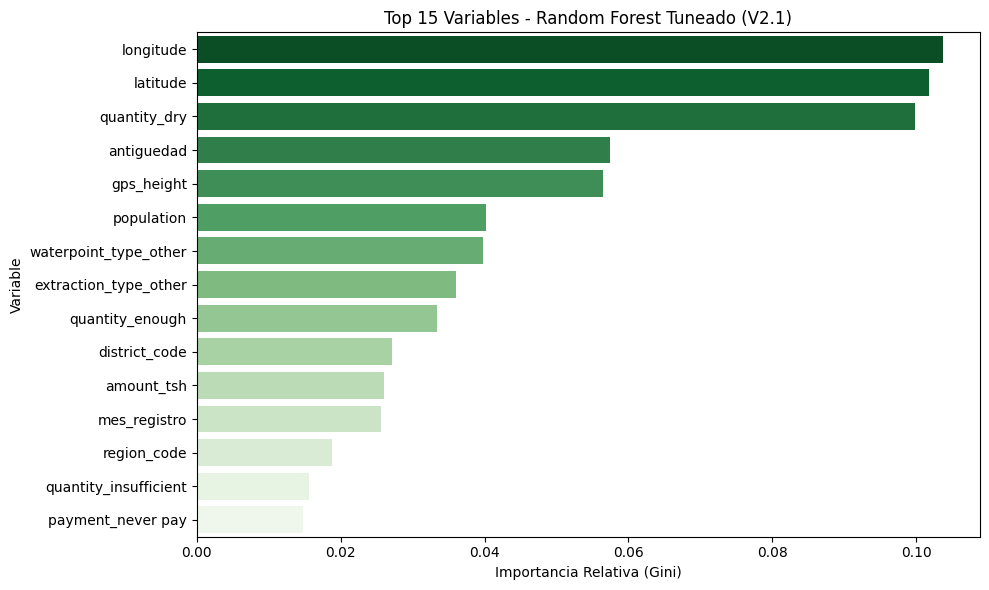

Análisis de estacionalidad: la variable 'mes_registro' ocupa el puesto 9 en importancia global.


In [6]:
prep_tuneado = modelo_rf_tuneado.named_steps['preprocessor']
rf_tuneado = modelo_rf_tuneado.named_steps['classifier']

nombres_tuneado = [n.split('__')[-1] for n in prep_tuneado.get_feature_names_out()]
importancias_tuneada = rf_tuneado.feature_importances_

df_imp_tuneado = pd.DataFrame({
    'Variable': nombres_tuneado,
    'Importancia': importancias_tuneada}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importancia',
    y='Variable',
    data=df_imp_tuneado.head(15),
    palette='Greens_r',
    hue='Variable',
    legend=False)
plt.title('Top 15 Variables - Random Forest Tuneado (V2.1)')
plt.xlabel('Importancia Relativa (Gini)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

posicion_mes = df_imp_tuneado[df_imp_tuneado['Variable'] == 'mes_registro'].index.tolist()
if posicion_mes:
    print(f"Análisis de estacionalidad: la variable 'mes_registro' ocupa el puesto {posicion_mes[0] + 1} en importancia global.")

## **PREDICCIÓN Y EXPORTACIÓN**

In [7]:
X_test_clean = preprocesado_estructural_v2_1(X_test_original)
predicciones = modelo_rf_tuneado.predict(X_test_clean)

mapeo_inverso = {0: 'non functional', 1: 'functional needs repair', 2: 'functional'}
df_submission = pd.DataFrame({
    'id': X_test_original.index,
    'status_group': pd.Series(predicciones).map(mapeo_inverso)})

nombre_archivo = 'pipeline_tuneado_v4_submission.csv'
#df_submission.to_csv(nombre_archivo, index=False)

df_submission.head(5)

,id,status_group
0,50785,non functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


## **MEJORA DEL ANTERIOR MODELO + UNA GEOGRAFÍA SEGURA**

El Random Forest base generaliza muy bien, pero le falta contexto espacial, por lo que la solución es rescatar el `LGA` y el `Basin`, ya que son zonas geográficas lo suficientemente amplias como para tener buenos históricos de datos, pero lo suficientemente específicas para identificar áreas con problemas crónicos de agua. Usaremos `TargetEncoder` para traducirlas a probabilidades.

In [11]:
def preprocesado_geo(df):
    df_clean = df.copy()
    df_clean['antiguedad'] = df_clean['date_recorded'].dt.year - df_clean['construction_year']
    df_clean['mes_registro'] = df_clean['date_recorded'].dt.month
    df_clean.drop(columns=['date_recorded', 'construction_year'], inplace=True)

    columnas_a_borrar = [
        'recorded_by', 'num_private', 'wpt_name', 'scheme_name',
        'subvillage', 'ward', 'extraction_type_group', 'extraction_type_class',
        'management_group', 'scheme_management', 'payment_type', 'quality_group',
        'quantity_group', 'source_type', 'source_class', 'waterpoint_type_group',
        'funder', 'installer']

    df_clean.drop(columns=columnas_a_borrar, inplace=True, errors='ignore')

    for col in ['longitude', 'population', 'gps_height']:
        df_clean[col] = df_clean[col].replace(0, np.nan)
    df_clean['antiguedad'] = df_clean['antiguedad'].apply(lambda x: np.nan if x > 100 or x < 0 else x)
    df_clean['latitude'] = df_clean['latitude'].apply(lambda x: np.nan if x > -1e-6 else x)
    return df_clean

X_clean_geo = preprocesado_geo(X_train_original)
X_train_geo, X_val_geo, y_train_geo, y_val_geo = train_test_split(X_clean_geo, y, test_size=0.2, random_state=42, stratify=y)

# Agrupamos variables
num_features_geo = X_train_geo.select_dtypes(include=[np.number]).columns.tolist()
cat_high_geo = ['lga']
cat_low_geo = [col for col in X_train_geo.select_dtypes(exclude=[np.number]).columns if col not in cat_high_geo]

num_transformer = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
target_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('target_enc', TargetEncoder(smooth="auto"))])

preprocessor_geo = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features_geo),
    ('cat_low', cat_transformer, cat_low_geo),
    ('cat_high', target_transformer, cat_high_geo)])

modelo_rf_geo = Pipeline(steps=[
    ('preprocessor', preprocessor_geo),
    ('classifier', RandomForestClassifier(n_estimators=500, max_depth=25, min_samples_split=5, random_state=42, n_jobs=-1))])

modelo_rf_geo.fit(X_train_geo, y_train_geo)
score_geo = modelo_rf_geo.score(X_val_geo, y_val_geo)
print("-" * 40)
print(f"PRECISIÓN: {score_geo * 100:.2f}%")
print("-" * 40)

----------------------------------------
PRECISIÓN: 81.24%
----------------------------------------


## **INTERPRETABILIDAD**

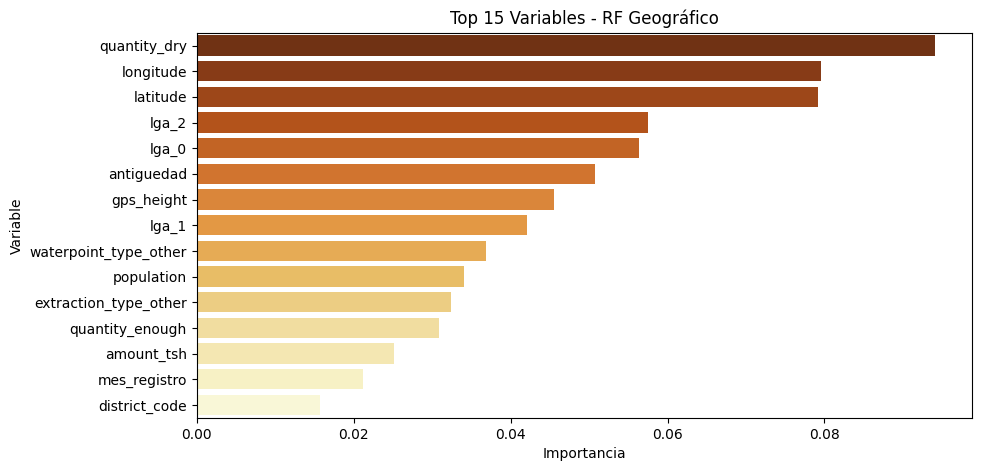

In [12]:
prep_geo = modelo_rf_geo.named_steps['preprocessor']
rf_geo = modelo_rf_geo.named_steps['classifier']

nombres_geo = [n.split('__')[-1] for n in prep_geo.get_feature_names_out()]
df_imp_geo = pd.DataFrame({'Variable': nombres_geo, 'Importancia': rf_geo.feature_importances_}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importancia', y='Variable', data=df_imp_geo.head(15), palette='YlOrBr_r', hue='Variable', legend=False)
plt.title('Top 15 Variables - RF Geográfico')
plt.show()

## **PREDICCIÓN Y EXPORTACIÓN**

In [13]:
X_test_geo = preprocesado_geo(X_test_original)
predicciones_geo = modelo_rf_geo.predict(X_test_geo)

df_sub_geo = pd.DataFrame({
    'id': X_test_original.index,
    'status_group': pd.Series(predicciones_geo).map({0: 'non functional', 1: 'functional needs repair', 2: 'functional'})})

#df_sub_geo.to_csv('pipeline_tuneado_geografico_v4_submission.csv', index=False)
df_sub_geo.head(5)

,id,status_group
0,50785,non functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


## **MEJORA DEL ANTERIOR MODELO: EXTRA TREES CLASSIFIER**

El Extremely Randomized Trees funciona igual que un Random Forest, pero añade un nivel de aleatoriedad extra a la hora de decidir por dónde cortar las ramas de decisión. Al ser "más caótico" en el entrenamiento, es sorprendentemente bueno evitando el overfitting.

In [14]:
modelo_extra_trees = Pipeline(steps=[
    ('preprocessor', preprocessor_geo),
    ('classifier', ExtraTreesClassifier(
        n_estimators=500,
        max_depth=25,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1))])

modelo_extra_trees.fit(X_train_geo, y_train_geo)
score_et = modelo_extra_trees.score(X_val_geo, y_val_geo)
print("-" * 40)
print(f"PRECISIÓN EXTRA TREES: {score_et * 100:.2f}%")
print("-" * 40)

----------------------------------------
PRECISIÓN EXTRA TREES: 80.35%
----------------------------------------


## **INTERPRETABILIDAD EXTRA TREES CLASSIFIER**

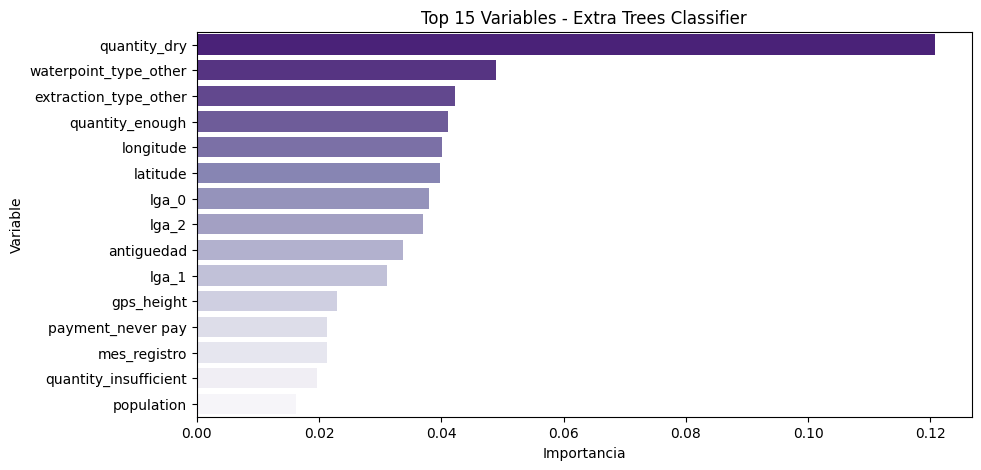

In [15]:
et_clasificador = modelo_extra_trees.named_steps['classifier']
df_imp_et = pd.DataFrame({'Variable': nombres_geo, 'Importancia': et_clasificador.feature_importances_}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importancia', y='Variable', data=df_imp_et.head(15), palette='Purples_r', hue='Variable', legend=False)
plt.title('Top 15 Variables - Extra Trees Classifier')
plt.show()

## **PREDICCIÓN Y EXPORTACIÓN**

In [16]:
predicciones_et = modelo_extra_trees.predict(X_test_geo)

df_sub_et = pd.DataFrame({
    'id': X_test_original.index,
    'status_group': pd.Series(predicciones_et).map({0: 'non functional', 1: 'functional needs repair', 2: 'functional'})})

#df_sub_et.to_csv('extra_trees_classifier_v4_submission.csv', index=False)
df_sub_et.head(5)

,id,status_group
0,50785,non functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional
